# Vietnamese-accented English ASR: fine-tuning and validation
This trains English character CTC, separately from phoneme-B. All references are corpus orthographic transcripts. Speaker and normalized prompt holdouts are disjoint. Test is excluded from checkpoint selection. Results on one Vietnamese test speaker do not establish general conversational or pronunciation accuracy.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/asr_vietnamese_english.json').is_file())
OUT = ROOT/'data/generated/asr-vietnamese-english-v1'
config = json.loads((ROOT/'configs/asr_vietnamese_english.json').read_text())
manifest = json.loads((ROOT/config['dataset_dir']/'manifest.json').read_text())
results = json.loads((OUT/'results.json').read_text())
pd.DataFrame(manifest['parts']).T[['count','hours','max_seconds']]

,count,hours,max_seconds
train,2445,2.494734,7.977959
validation,104,0.103821,6.954762
test,111,0.134233,8.098685


## Run training manually
These commands never execute when the notebook is opened. The existing run is preserved; use `--resume` only for an interrupted matching run.

In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    import subprocess, sys
    subprocess.run([sys.executable, '-X','utf8','scripts/train_asr_vi.py','--prepare'],cwd=ROOT,check=True)
    subprocess.run([sys.executable, '-X','utf8','scripts/train_asr_vi.py','--run'],cwd=ROOT,check=True)
else:
    print('Training disabled in this cell. Recorded results are visualized below.')

Training disabled in this cell. Recorded results are visualized below.


## Learning curves
Training loss is diagnostic. Lowest validation WER selects the checkpoint; test is evaluated only after selection.

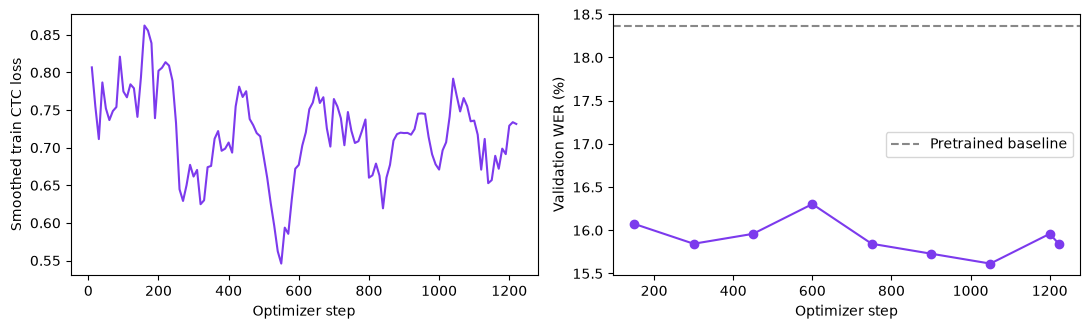

In [3]:
history = pd.read_json(ROOT/config['run_dir']/'training_history.jsonl', lines=True)
validation = pd.DataFrame(json.loads((ROOT/config['run_dir']/'history.json').read_text()))
fig, axes = plt.subplots(1,2,figsize=(11,3.4))
axes[0].plot(history.step,history.loss.rolling(10,min_periods=1).mean(),color='#7c3aed')
axes[0].set(xlabel='Optimizer step',ylabel='Smoothed train CTC loss')
axes[1].plot(validation.step,validation.validation.map(lambda r:r['wer']*100),marker='o',color='#7c3aed')
axes[1].axhline(results['baseline_validation']['wer']*100,color='#888888',linestyle='--',label='Pretrained baseline')
axes[1].set(xlabel='Optimizer step',ylabel='Validation WER (%)'); axes[1].legend()
fig.tight_layout();fig.savefig(OUT/'learning-curves.png',dpi=160);plt.show()

## Matched before/after results
WER and CER measure transcription errors, not pronunciation correctness. These are a small read-speech benchmark; errors in corpus references may affect results.

,split,model,utterances,WER (%),CER (%)
0,validation,Before,104,18.370,7.384
1,validation,After,104,15.614,6.201
2,test,Before,111,43.011,19.197
3,test,After,111,37.928,16.676


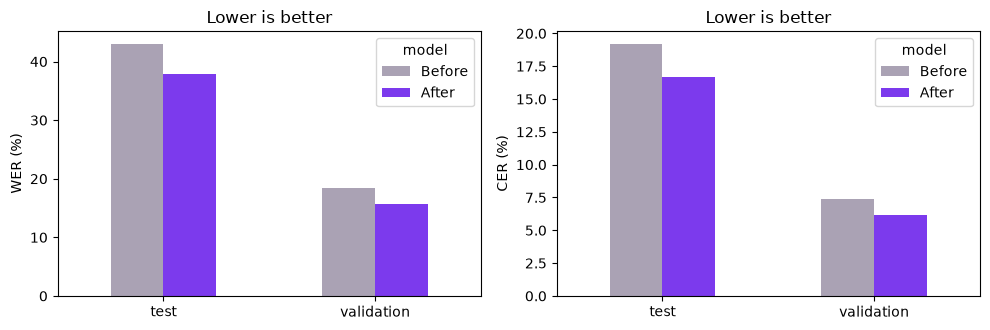

In [4]:
rows=[]
for split,before,after in [('validation','baseline_validation','best_validation'),('test','baseline_test','trained_test')]:
    for label,key in [('Before',before),('After',after)]:
        r=results[key];rows.append({'split':split,'model':label,'utterances':r['utterances'],'WER (%)':r['wer']*100,'CER (%)':r['cer']*100})
table=pd.DataFrame(rows);display(table.round(3));table.to_csv(OUT/'metrics.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
for ax,metric in zip(axes,['WER (%)','CER (%)']):
    table.pivot(index='split',columns='model',values=metric)[['Before','After']].plot.bar(ax=ax,color=['#aaa2b4','#7c3aed'],rot=0)
    ax.set_ylabel(metric);ax.set_xlabel('');ax.set_title('Lower is better')
fig.tight_layout();fig.savefig(OUT/'before-after.png',dpi=160);plt.show()

## Previously supplied development recordings
These recordings were inspected during planning. They are not the held-out benchmark. Reference text was not supplied to the decoder. This comparison uses GPU BF16 greedy decoding, while the demo runs inference on CPU float32.

In [5]:
examples=OUT/'development_examples.json'
if examples.is_file():
    examples=json.loads(examples.read_text())['cases']
    display(pd.DataFrame([{'reference':r['reference'],'before':r['before']['transcript'],'after':r['after']['transcript'],'WER before (%)':r['before']['wer_vs_intended']*100,'WER after (%)':r['after']['wer_vs_intended']*100} for r in examples]))
else:
    print('Development comparison pending.')

,reference,before,after,WER before (%),WER after (%)
0,It was difficult to get there,IT WAS THE DIVICOTE TRUE GETESIR,IT WAS THE DIFVICUTO TRUE GETESAIR,66.666667,66.666667
1,End of the road for some players,AND THOU THEYLL O THE FOR SAMUN PLAY ARMS,AND THOUG THEY LO THE FOR SAMON PLAY ARMS,114.285714,114.285714
2,Zero five eight three,NAWHA IT U SAY,TA WHA ET US SAY,100.000000,125.000000


## Weight changes
CNN stays frozen; attention and character-CTC weights are updated.

In [6]:
weights=OUT/'weight_changes.json'
if weights.is_file():
    display(pd.DataFrame(json.loads(weights.read_text())).T)

,changed,max_absolute_change
cnn,False,0.0
transformer_attention,True,0.00032
ctc_head,True,0.00279


## Qwen grammar adapter
Matched text-only development probe; format compliance and chrF are not human grammar quality, semantic faithfulness, official ERRANT F0.5 or JFLEG GLEU.

In [7]:
comparison=ROOT/'data/generated/grammar-adapter-demo-v1/comparison.json'
if comparison.is_file():
    q=json.loads(comparison.read_text()); qr=[]
    for model in ['before','after']:
        for task,r in q[model]['tasks'].items():
            qr.append({'model':model,'task':task,'rows':r['rows'],'valid JSON (%)':r['valid_json_rate']*100,'reference chrF':r['chrf']})
    display(pd.DataFrame(qr).round(3))
else:
    print('Grammar comparison pending.')

,model,task,rows,valid JSON (%),reference chrF
0,before,grammar_corrected,8,0.0,0.000
1,before,natural,8,0.0,0.000
2,after,grammar_corrected,8,100.0,86.952
3,after,natural,8,100.0,93.778


## Demo model provenance
Incomplete ASR runs and runs without improved validation WER use the base model. The grammar adapter requires a completed checksum-matched validation record. The conversation model remains base Qwen.

In [8]:
import sys
sys.path.insert(0,str(ROOT/'src'))
from mdd.demo_model_registry import asr_selection, grammar_selection
for task,selection in [('ASR',asr_selection(ROOT)),('Grammar',grammar_selection(ROOT))]:
    print(task,selection['id'])
print('Conversation: Qwen3-0.6B base; pronunciation: phoneme-B unchanged.')

ASR wav2vec2-vi-en-v1
Grammar qwen-grammar
Conversation: Qwen3-0.6B base; pronunciation: phoneme-B unchanged.
